# LSTM workload forecasting: standalone Kaggle notebook, all 4 table configurations + TPR vs SR

Standalone version of `lstm_training.py` (`grass-overflow/ML_Proj`); no repo clone and no `util/` or `models/` imports.

It reproduces the four **LSTM** rows of the paper's Table 1 (Conv1D -> LSTM -> MLP -> point forecast, trained with MSE):

| Label | Training | Prediction | Fits |
|---|---|---|---|
| **S-U-LSTM** | single trace | univariate (CPU or memory) | 12 traces x 2 = 24 |
| **S-B-LSTM** | single trace | bivariate (CPU + memory) | 12 |
| **M-U-LSTM** | all 12 traces together | univariate | 2 (one per resource) |
| **M-B-LSTM** | all 12 traces together | bivariate | 1 |

Each fit runs **500 epochs, 1 iteration** with the saved hyperparameters of that configuration. Table 1 = mean MSE/MAE over the 12 traces' test splits.

**TPR vs SR data:** LSTM gives a point forecast, so service-level upper bounds are built as in the repo: `upper = forecast + q-quantile of the trace's validation residuals`, for 11 service levels q = 0.90..0.99 and 0.995. SR = % of test targets <= upper; TPR = 100 x sum(upper) / sum(actual). Per-trace values, the 12-trace averages and the plots are all saved.

**Setup:** Add Input -> your **ML_PROJ_DATASET**, set Accelerator to GPU, Run All. Results and models are written to `/kaggle/working/lstm_output/` after every fit. If the session stops, re-run and it resumes (finished fits are skipped).

In [1]:
# ---------- CONFIG ----------
import os, glob, json, time, zipfile
from pathlib import Path
import numpy as np
import pandas as pd

MODES = ["S-U", "S-B", "M-U", "M-B"]   # any subset, e.g. ["M-B"] for a quick run
EPOCHS = 500
ITERATIONS = 1             # single training run per fit
WIN, HORIZON = 288, 2
TRAIN_SPLIT = 0.8          # first 80% of each trace = train + validation, last 20% = test
VAL_SPLIT = 0.2            # last 20% of the training part (chronological) = validation / residual calibration
SEED = 0
RESUME = True              # skip fits already recorded in lstm_output/LSTM_fit_log.csv
LOG_EVERY = 25             # print a progress line every N epochs

# False = run all 500 epochs (best-val-loss weights are restored at the end).
# True  = stop early if val_loss doesn't improve for PATIENCE epochs.
EARLY_STOPPING = False
PATIENCE = 50

MODEL_NAME = "LSTM"
TRACES = ["gc11", "gc19_a", "gc19_b", "gc19_c", "gc19_d", "gc19_e", "gc19_f", "gc19_g", "gc19_h",
          "ali18", "ali20_c", "ali20_g"]
RESOURCES = ["avgcpu", "avgmem"]      # channel 0 = CPU ("processing units"), channel 1 = memory
SERVICE_LEVELS = [0.90, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 0.995]

# Paper Table 1, LSTM rows: (CPU MSE, CPU MAE, Memory MSE, Memory MAE)
PAPER = {"S-U-LSTM": (0.0041, 0.0457, 0.0042, 0.0425), "S-B-LSTM": (0.0047, 0.0500, 0.0054, 0.0487),
         "M-U-LSTM": (0.0044, 0.0474, 0.0048, 0.0447), "M-B-LSTM": (0.0044, 0.0479, 0.0044, 0.0438)}

# Saved hyperparameters of every configuration (from the repo's hyperparams/ CSVs).
# Keys: "S-U|<trace>|<cpu|mem>", "S-B|<trace>", "M-U|<cpu|mem>", "M-B"
HP = json.loads('''{"S-U|gc11|cpu":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc11|mem":{"first_conv_dim":64,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-B|gc11":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_a|cpu":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_a|mem":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_a":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.001},"S-U|gc19_b|cpu":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_b|mem":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_b":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_c|cpu":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_c|mem":{"first_conv_dim":128,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_c":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_d|cpu":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_d|mem":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_d":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_e|cpu":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_e|mem":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_e":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_f|cpu":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_f|mem":{"first_conv_dim":128,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.0001},"S-B|gc19_f":{"first_conv_dim":128,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_g|cpu":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_g|mem":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_g":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_h|cpu":{"first_conv_dim":128,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_h|mem":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_h":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.0001},"S-U|ali18|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali18|mem":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali18":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|ali20_c|cpu":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_c|mem":{"first_conv_dim":128,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-B|ali20_c":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.001},"S-U|ali20_g|cpu":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_g|mem":{"first_conv_dim":128,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.001},"S-B|ali20_g":{"first_conv_dim":128,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"M-U|cpu":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":8,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"M-U|mem":{"first_conv_dim":16,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":3,"second_lstm_dim":32,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,16],"batch_size":1024,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"M-B":{"first_conv_dim":16,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,32],"batch_size":128,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001}}''')

OUT = Path("/kaggle/working/lstm_output") if Path("/kaggle/working").exists() else Path("lstm_output")
for sub in ("models", "history", "ckpt", "predictions"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE (500-epoch fits on CPU will be extremely slow; set Accelerator to GPU)")

TensorFlow 2.20.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load the 12 traces from ML_PROJ_DATASET

Looks under `/kaggle/input` for the 12 CSVs (`time, avgcpu, avgmem`), so it works whatever the exact mount path is. The data is already normalized, so no extra scaler is applied.

In [2]:
DATASET_SLUG = "ml-proj-dataset"
def norm(x): return x.lower().replace("_", "-")

all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
preferred = [p for p in all_csvs if DATASET_SLUG in norm(p)]
found = {}
for p in preferred + all_csvs:
    stem = Path(p).stem
    if stem in TRACES and stem not in found:
        found[stem] = p
missing = [t for t in TRACES if t not in found]
if missing:
    raise FileNotFoundError(f"Missing traces {missing}. Attach ML_PROJ_DATASET via Add Input. "
                            f"CSVs visible under /kaggle/input: {sorted(all_csvs)[:30]}")

series = {}
for t in TRACES:
    df = pd.read_csv(found[t])
    assert {"avgcpu", "avgmem"} <= set(df.columns), f"{t}: expected avgcpu/avgmem, got {list(df.columns)}"
    series[t] = df[RESOURCES].to_numpy(dtype=np.float32)
    print(f"{t:8s} {len(df):6d} rows  <- {found[t]}")

gc11       8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc11.csv
gc19_a     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_a.csv
gc19_b     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_b.csv
gc19_c     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_c.csv
gc19_d     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_d.csv
gc19_e     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_e.csv
gc19_f     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_f.csv
gc19_g     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_g.csv
gc19_h     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_h.csv
ali18      2016 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali18.csv
ali20_c   13904 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali20_c.csv
a

## 2. Windows

Per trace: input = 288 consecutive steps, target = the value `HORIZON` steps past the step right after the window. The first 80% of windows are the training part and the rest is the test split. The **last 20% of the training part (in time order) is the validation set**: it selects the best epoch and calibrates the service-level bounds, so it never overlaps the training windows. Windows are built once for both channels and sliced to CPU-only / memory-only for the univariate configurations; multi-trace configurations concatenate the 12 traces.

In [3]:
from numpy.lib.stride_tricks import sliding_window_view

def make_windows(arr, w, h):
    n = len(arr)
    N = n - w - h
    X = np.ascontiguousarray(np.transpose(sliding_window_view(arr, w, axis=0)[:N], (0, 2, 1)))   # (N, w, C)
    y = arr[w + h : w + h + N]                                                                    # (N, C)
    return X, y

WINDOWS = {}   # trace -> dict(tr=(X, y), va=(X, y), te=(X, y)), both channels
for t in TRACES:
    X, y = make_windows(series[t], WIN, HORIZON)
    s = int(len(series[t]) * TRAIN_SPLIT)       # train+val windows: [:s]; test windows: [s:]
    v = int(s * (1 - VAL_SPLIT))                # train: [:v]; validation: [v:s]
    WINDOWS[t] = dict(tr=(X[:v], y[:v]), va=(X[v:s], y[v:s]), te=(X[s:], y[s:]))
    print(f"{t:8s} train {v:5d} | val {s - v:5d} | test {len(y) - s:5d}")

def get_data(train_traces, cols):
    cat = lambda part, i: np.concatenate([(WINDOWS[t][part][0][:, :, cols] if i == 0 else WINDOWS[t][part][1][:, cols]) for t in train_traces])
    return cat("tr", 0), cat("tr", 1), cat("va", 0), cat("va", 1)

gc11     train  5344 | val  1337 | test  1381
gc19_a   train  5344 | val  1337 | test  1381
gc19_b   train  5344 | val  1337 | test  1381
gc19_c   train  5344 | val  1337 | test  1381
gc19_d   train  5344 | val  1337 | test  1381
gc19_e   train  5344 | val  1337 | test  1381
gc19_f   train  5344 | val  1337 | test  1381
gc19_g   train  5344 | val  1337 | test  1381
gc19_h   train  5344 | val  1337 | test  1381
ali18    train  1289 | val   323 | test   114
ali20_c  train  8898 | val  2225 | test  2491
ali20_g  train  8898 | val  2225 | test  2491


## 3. Model: LSTM (same architecture as `models/LSTM.py`)

Conv1D (causal) x `cnn_layers` -> LSTM -> MLP -> Dense -> Dense(number of targets), trained with MSE and the optimizer / batch size from that configuration's saved hyperparameters.

In [4]:
def make_optimizer(p):
    o = p["optimizer"]
    if o == "adam":    return keras.optimizers.Adam(learning_rate=p["lr"], weight_decay=p["decay"])
    if o == "rmsprop": return keras.optimizers.RMSprop(learning_rate=p["lr"])
    if o == "nadam":   return keras.optimizers.Nadam(learning_rate=p["lr"])
    if o == "sgd":     return keras.optimizers.SGD(learning_rate=p["lr"], momentum=p["momentum"])
    raise ValueError(o)

def build_model(input_shape, n_targets, p, name):
    inp = keras.Input(shape=input_shape)
    x = inp
    for _ in range(p["cnn_layers"]):
        x = layers.Conv1D(p["first_conv_dim"], p["first_conv_kernel"], strides=1, padding="causal",
                          activation=p["first_conv_activation"])(x)
    x = layers.LSTM(p["second_lstm_dim"])(x)
    for d in p["mlp_units"]:
        x = layers.Dense(d, activation="relu")(x)
    x = layers.Dense(p["first_dense_dim"], activation=p["first_dense_activation"])(x)
    out = layers.Dense(n_targets)(x)
    model = keras.Model(inp, out, name=name)
    model.compile(loss="mean_squared_error", optimizer=make_optimizer(p), metrics=["mae"])
    return model

## 4. Run configurations: 500 epochs, 1 iteration per fit

Per fit it saves the best-`val_loss` model (`models/*.keras`), the per-epoch history (`history/*.csv`), and updates all result CSVs. Service-level bounds follow the repo's LSTM comparison: for each test trace, `upper = forecast + quantile_q(validation residuals of that trace)`.

In [5]:
def jobs_for(mode):
    jobs = []
    if mode == "S-U":
        for t in TRACES:
            for r, c in (("cpu", 0), ("mem", 1)):
                jobs.append(dict(mode=mode, train=[t], cols=[c], hp=f"S-U|{t}|{r}", tag=f"{t}__{r}"))
    elif mode == "S-B":
        for t in TRACES:
            jobs.append(dict(mode=mode, train=[t], cols=[0, 1], hp=f"S-B|{t}", tag=t))
    elif mode == "M-U":
        for r, c in (("cpu", 0), ("mem", 1)):
            jobs.append(dict(mode=mode, train=TRACES, cols=[c], hp=f"M-U|{r}", tag=f"all__{r}"))
    elif mode == "M-B":
        jobs.append(dict(mode=mode, train=TRACES, cols=[0, 1], hp="M-B", tag="all"))
    for j in jobs:
        j["label"] = f"{mode}-{MODEL_NAME}"
        j["eval"] = j["train"]          # test split of every trace the model was trained on (1 for S-*, 12 for M-*)
    return jobs

class Progress(keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == self.params.get("epochs"):
            print(f"    epoch {epoch+1:4d}/{self.params.get('epochs')}  loss {logs['loss']:.5f}  "
                  f"val_loss {logs['val_loss']:.5f}  [{(time.time()-self.t0)/60:.1f} min]", flush=True)

# ---- result state (resumable) ----
FILES = dict(metrics=OUT / f"{MODEL_NAME}_model_metrics.csv", service=OUT / f"{MODEL_NAME}_service_level_metrics.csv",
             fits=OUT / f"{MODEL_NAME}_fit_log.csv")
def pred_path(mode): return OUT / "predictions" / f"{MODEL_NAME}_{mode}_predictions.csv"

state = dict(metrics=[], service=[], fits=[], preds={})
if RESUME and FILES["fits"].exists():
    for k in ("metrics", "service", "fits"):
        state[k] = pd.read_csv(FILES[k]).to_dict("records")
    for m in MODES:
        if pred_path(m).exists():
            state["preds"][m] = pd.read_csv(pred_path(m))
    print(f"Resuming: {len(state['fits'])} fits already finished")
done = {(f["model"], f["tag"]) for f in state["fits"]}

def evaluate(model, job):
    for t in job["eval"]:
        Xva, yva = WINDOWS[t]["va"][0][:, :, job["cols"]], WINDOWS[t]["va"][1][:, job["cols"]]
        Xte, yte = WINDOWS[t]["te"][0][:, :, job["cols"]], WINDOWS[t]["te"][1][:, job["cols"]]
        val_res = yva - model.predict(Xva, batch_size=1024, verbose=0)       # validation residuals of this trace
        pred = model.predict(Xte, batch_size=1024, verbose=0)
        for k, c in enumerate(job["cols"]):
            r = RESOURCES[c]
            err = yte[:, k] - pred[:, k]
            state["metrics"].append(dict(model=job["label"], dataset=t, resource=r, MSE=float(np.mean(err**2)),
                                         MAE=float(np.mean(np.abs(err))), n_test=len(err), training=job["tag"]))
            demand = float(np.sum(yte[:, k]))
            for q in SERVICE_LEVELS:
                a = 1.0 - q
                upper = pred[:, k] + np.quantile(val_res[:, k], q)
                lo = pred[:, k] + np.quantile(val_res[:, k], a / 2)
                hi = pred[:, k] + np.quantile(val_res[:, k], 1 - a / 2)
                sr = float(np.mean(yte[:, k] <= upper) * 100)
                state["service"].append(dict(model=job["label"], dataset=t, resource=r, service_level=q, SR=sr,
                                             TPR=float(100 * np.sum(upper) / demand) if demand > 0 else float("nan"),
                                             coverage=float(np.mean((yte[:, k] >= lo) & (yte[:, k] <= hi)) * 100),
                                             calibration_error=sr - q * 100, mean_interval_width=float(np.mean(hi - lo))))
            pf = pd.DataFrame(dict(model=job["label"], dataset=t, resource=r, step=np.arange(len(err)),
                                   pred=pred[:, k], label=yte[:, k]))
            state["preds"][job["mode"]] = pd.concat([state["preds"].get(job["mode"]), pf], ignore_index=True)

def flush():
    pd.DataFrame(state["metrics"]).to_csv(FILES["metrics"], index=False)
    pd.DataFrame(state["service"]).to_csv(FILES["service"], index=False)
    pd.DataFrame(state["fits"]).to_csv(FILES["fits"], index=False)
    for m, df in state["preds"].items():
        df.to_csv(pred_path(m), index=False)

def run_job(job):
    p = HP[job["hp"]]
    Xtr, ytr, Xva, yva = get_data(job["train"], job["cols"])
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    name = f"{job['label']}__{job['tag']}"
    model = build_model(Xtr.shape[1:], ytr.shape[1], p, name.replace("-", "_"))
    best_w = OUT / "ckpt" / f"{name}.weights.h5"
    cbs = [keras.callbacks.ModelCheckpoint(str(best_w), monitor="val_loss", mode="min", save_best_only=True,
                                           save_weights_only=True, verbose=0),
           keras.callbacks.CSVLogger(str(OUT / "history" / f"{name}.csv")), Progress()]
    if EARLY_STOPPING:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=PATIENCE,
                                                 restore_best_weights=True, verbose=0))
    print(f"  {name} | train {Xtr.shape} val {Xva.shape[0]} | batch {p['batch_size']} | {p['optimizer']} lr {p['lr']}", flush=True)
    t0 = time.time()
    h = model.fit(Xtr, ytr, epochs=EPOCHS, batch_size=p["batch_size"], validation_data=(Xva, yva),
                  shuffle=True, verbose=0, callbacks=cbs)
    minutes = (time.time() - t0) / 60
    model.load_weights(str(best_w))                          # restore best-val-loss weights
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    model_file = OUT / "models" / f"{name}.keras"
    model.save(model_file)
    evaluate(model, job)
    state["fits"].append(dict(model=job["label"], tag=job["tag"], hp=job["hp"], resources="+".join(RESOURCES[c] for c in job["cols"]),
                              n_train=len(Xtr), n_val=len(Xva), epochs_run=len(h.history["loss"]), best_epoch=best_epoch,
                              best_val_loss=float(min(h.history["val_loss"])), train_minutes=round(minutes, 2),
                              batch_size=p["batch_size"], optimizer=p["optimizer"], model_file=model_file.name))
    flush()
    last = [m for m in state["metrics"] if m["training"] == job["tag"] and m["model"] == job["label"]]
    print(f"  -> done in {minutes:.1f} min, best epoch {best_epoch}, mean test MSE {np.mean([m['MSE'] for m in last]):.5f}", flush=True)
    del model, Xtr, ytr, Xva, yva

t_all = time.time()
for it in range(ITERATIONS):
    for mode in MODES:
        jobs = jobs_for(mode)
        print(f"\n===== {mode}-{MODEL_NAME}: {len(jobs)} fit(s) | ITERATION {it} =====", flush=True)
        for i, job in enumerate(jobs, 1):
            if (job["label"], job["tag"]) in done:
                print(f"  [{i}/{len(jobs)}] {job['tag']}: already done, skipping"); continue
            print(f"  [{i}/{len(jobs)}]", flush=True)
            run_job(job)
print(f"\nAll fits finished in {(time.time() - t_all)/60:.1f} min")


===== S-U-LSTM: 24 fit(s) | ITERATION 0 =====
  [1/24]


I0000 00:00:1791430514.614742      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791430514.618672      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  S-U-LSTM__gc11__cpu | train (5344, 288, 1) val 1337 | batch 512 | adam lr 0.001
    epoch    1/500  loss 0.05485  val_loss 0.07912  [0.1 min]
    epoch   25/500  loss 0.00374  val_loss 0.01757  [0.2 min]
    epoch   50/500  loss 0.00345  val_loss 0.01678  [0.4 min]
    epoch   75/500  loss 0.00339  val_loss 0.01620  [0.5 min]
    epoch  100/500  loss 0.00335  val_loss 0.01542  [0.7 min]
    epoch  125/500  loss 0.00332  val_loss 0.01603  [0.8 min]
    epoch  150/500  loss 0.00330  val_loss 0.01633  [1.0 min]
    epoch  175/500  loss 0.00325  val_loss 0.01653  [1.2 min]
    epoch  200/500  loss 0.00320  val_loss 0.01763  [1.3 min]
    epoch  225/500  loss 0.00313  val_loss 0.01908  [1.5 min]
    epoch  250/500  loss 0.00303  val_loss 0.02808  [1.6 min]
    epoch  275/500  loss 0.00291  val_loss 0.02456  [1.8 min]
    epoch  300/500  loss 0.00281  val_loss 0.02397  [1.9 min]
    epoch  325/500  loss 0.00258  val_loss 0.02277  [2.1 min]
    epoch  350/500  loss 0.00248  val_loss 0.03576

## 5. Table 1 (LSTM rows): mean over the 12 traces

Same layout as the paper's table (Processing units = CPU, Memory), with the paper's LSTM values next to this run for context.

Table 1 - average MSE/MAE over the 12 traces (processing units = CPU, memory)


,Model,CPU_MSE,CPU_MAE,Memory_MSE,Memory_MAE,traces
0,S-U-LSTM,0.0043,0.0476,0.0045,0.0443,12
1,S-B-LSTM,0.0049,0.0512,0.0048,0.0467,12
2,M-U-LSTM,0.0042,0.0467,0.0042,0.0430,12
3,M-B-LSTM,0.0047,0.0490,0.0046,0.0444,12



Same, next to the paper's values


,Model,CPU_MSE,paper_CPU_MSE,CPU_MAE,paper_CPU_MAE,Memory_MSE,paper_Memory_MSE,Memory_MAE,paper_Memory_MAE,traces
0,S-U-LSTM,0.0043,0.0041,0.0476,0.0457,0.0045,0.0042,0.0443,0.0425,12
1,S-B-LSTM,0.0049,0.0047,0.0512,0.0500,0.0048,0.0054,0.0467,0.0487,12
2,M-U-LSTM,0.0042,0.0044,0.0467,0.0474,0.0042,0.0048,0.0430,0.0447,12
3,M-B-LSTM,0.0047,0.0044,0.0490,0.0479,0.0046,0.0044,0.0444,0.0438,12


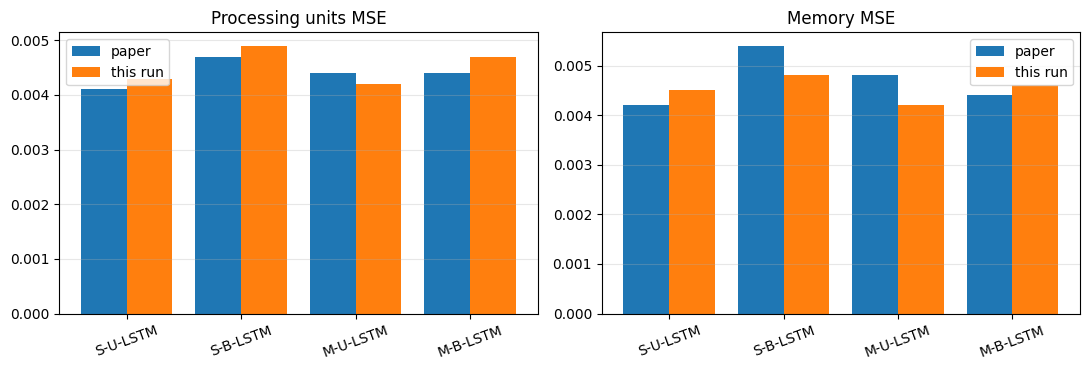


Per-fit log


,model,tag,n_train,n_val,epochs_run,best_epoch,best_val_loss,train_minutes,batch_size,optimizer
0,S-U-LSTM,gc11__cpu,5344,1337,500,180,0.014078,3.22,512,adam
1,S-U-LSTM,gc11__mem,5344,1337,500,488,0.005253,4.22,256,rmsprop
2,S-U-LSTM,gc19_a__cpu,5344,1337,500,334,0.005604,3.30,512,adam
3,S-U-LSTM,gc19_a__mem,5344,1337,500,151,0.004291,4.04,256,adam
4,S-U-LSTM,gc19_b__cpu,5344,1337,500,493,0.005309,3.18,256,rmsprop
5,S-U-LSTM,gc19_b__mem,5344,1337,500,386,0.003474,3.56,512,adam
6,S-U-LSTM,gc19_c__cpu,5344,1337,500,422,0.003815,3.03,1024,adam
7,S-U-LSTM,gc19_c__mem,5344,1337,500,117,0.004938,4.84,256,adam
8,S-U-LSTM,gc19_d__cpu,5344,1337,500,474,0.004216,2.48,512,adam
9,S-U-LSTM,gc19_d__mem,5344,1337,500,128,0.005342,4.03,256,adam


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display

metrics = pd.DataFrame(state["metrics"])
order = [f"{m}-{MODEL_NAME}" for m in ["S-U", "S-B", "M-U", "M-B"] if f"{m}-{MODEL_NAME}" in set(metrics["model"])]
agg = metrics.groupby(["model", "resource"]).agg(MSE=("MSE", "mean"), MAE=("MAE", "mean"), traces=("dataset", "nunique"))

rows, cmp_rows = [], []
for m in order:
    c, r = agg.loc[(m, "avgcpu")], agg.loc[(m, "avgmem")]
    rows.append({"Model": m, "CPU_MSE": c.MSE, "CPU_MAE": c.MAE, "Memory_MSE": r.MSE, "Memory_MAE": r.MAE, "traces": int(c.traces)})
    pm = PAPER[m]
    cmp_rows.append({"Model": m, "CPU_MSE": c.MSE, "paper_CPU_MSE": pm[0], "CPU_MAE": c.MAE, "paper_CPU_MAE": pm[1],
                     "Memory_MSE": r.MSE, "paper_Memory_MSE": pm[2], "Memory_MAE": r.MAE, "paper_Memory_MAE": pm[3], "traces": int(c.traces)})
table1 = pd.DataFrame(rows).round(4)
table1_cmp = pd.DataFrame(cmp_rows).round(4)
table1.to_csv(OUT / f"{MODEL_NAME}_table1.csv", index=False)
table1_cmp.to_csv(OUT / f"{MODEL_NAME}_table1_vs_paper.csv", index=False)

print("Table 1 - average MSE/MAE over the 12 traces (processing units = CPU, memory)")
display(table1)
print("\nSame, next to the paper's values")
display(table1_cmp)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(table1_cmp))
for ax, (col, pcol, ttl) in zip(axes, [("CPU_MSE", "paper_CPU_MSE", "Processing units MSE"), ("Memory_MSE", "paper_Memory_MSE", "Memory MSE")]):
    ax.bar(x - 0.2, table1_cmp[pcol], 0.4, label="paper"); ax.bar(x + 0.2, table1_cmp[col], 0.4, label="this run")
    ax.set_xticks(x, table1_cmp["Model"], rotation=20); ax.set_title(ttl); ax.legend(); ax.grid(axis="y", alpha=.3)
fig.tight_layout(); fig.savefig(OUT / f"{MODEL_NAME}_table1_vs_paper.png", dpi=150); plt.show()

print("\nPer-fit log")
display(pd.DataFrame(state["fits"])[["model", "tag", "n_train", "n_val", "epochs_run", "best_epoch", "best_val_loss", "train_minutes", "batch_size", "optimizer"]])

## 6. TPR vs SR data and plots

`LSTM_tpr_vs_sr_data.csv` is plot-ready: for every configuration, resource and service level it has the mean SR and TPR over the 12 traces (plus their std). The per-trace values are in `LSTM_service_level_metrics.csv` (columns `model, dataset, resource, service_level, SR, TPR`). Each point on a curve is one service level (0.90 ... 0.995).

,model,resource,service_level,SR_mean,SR_std,TPR_mean,TPR_std,n_traces
0,S-U-LSTM,avgcpu,0.90,90.026,3.887,120.968,26.544,12
5,S-U-LSTM,avgcpu,0.95,94.667,2.701,129.767,41.046,12
9,S-U-LSTM,avgcpu,0.99,98.580,1.049,146.069,57.984,12
11,S-U-LSTM,avgmem,0.90,90.353,3.403,119.670,21.428,12
16,S-U-LSTM,avgmem,0.95,95.212,2.111,126.199,26.609,12
20,S-U-LSTM,avgmem,0.99,98.726,0.946,151.822,73.521,12
22,S-B-LSTM,avgcpu,0.90,90.524,3.808,122.859,31.832,12
27,S-B-LSTM,avgcpu,0.95,94.752,2.353,130.763,44.384,12
31,S-B-LSTM,avgcpu,0.99,98.646,1.024,147.602,62.403,12
33,S-B-LSTM,avgmem,0.90,90.847,3.879,121.229,24.123,12


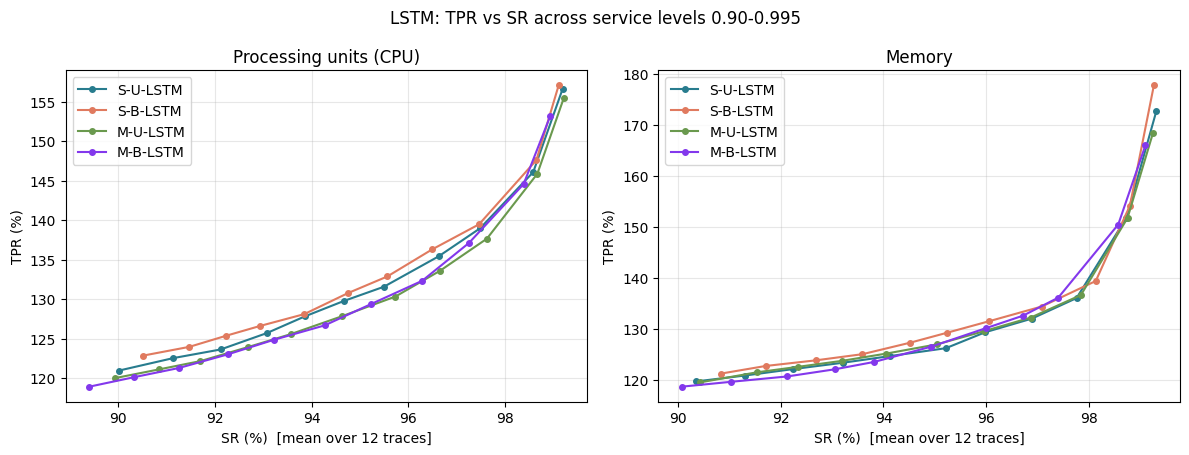

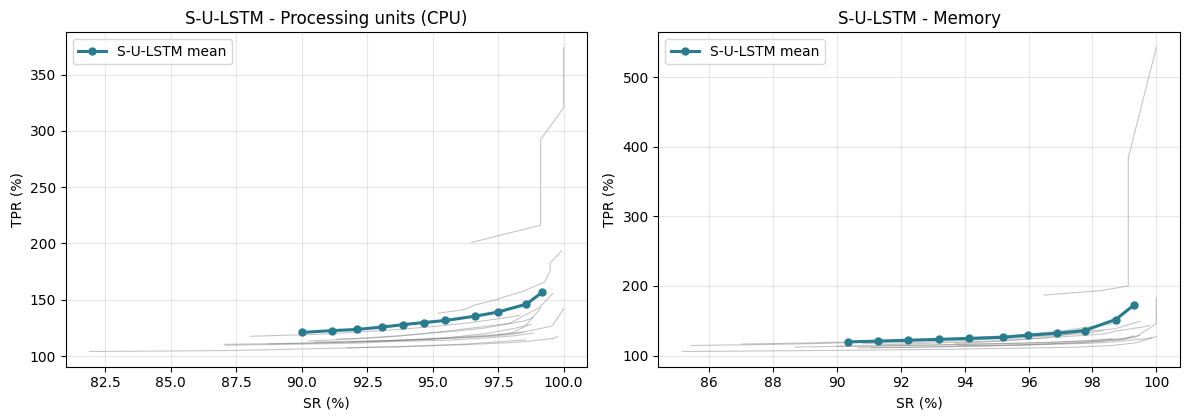

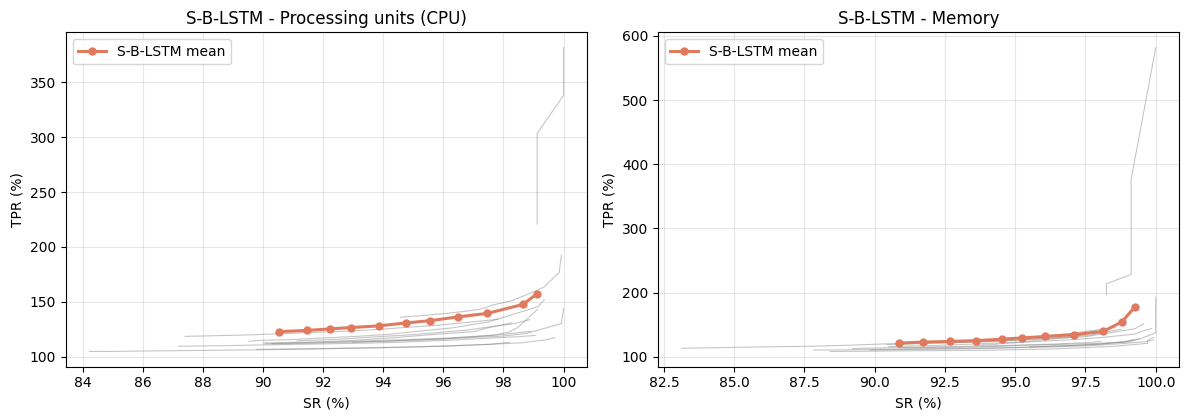

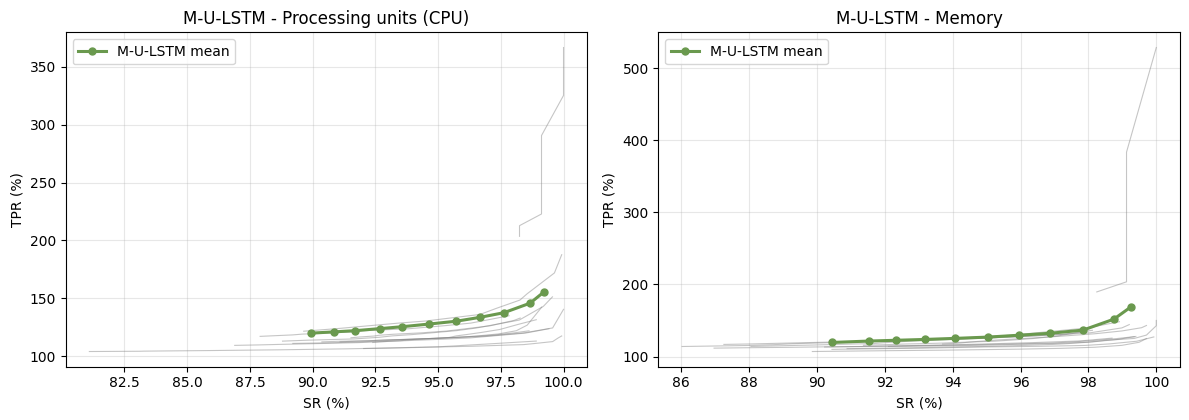

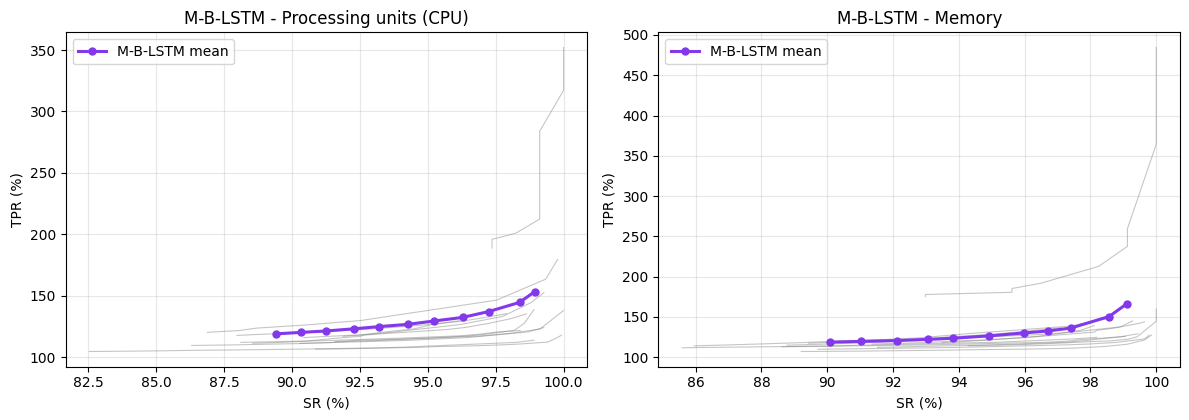

In [7]:
service = pd.DataFrame(state["service"])
tpr_sr = (service.groupby(["model", "resource", "service_level"])
          .agg(SR_mean=("SR", "mean"), SR_std=("SR", "std"), TPR_mean=("TPR", "mean"), TPR_std=("TPR", "std"), n_traces=("dataset", "nunique"))
          .reset_index())
tpr_sr["model"] = pd.Categorical(tpr_sr["model"], categories=order, ordered=True)
tpr_sr = tpr_sr.sort_values(["model", "resource", "service_level"]).reset_index(drop=True)
tpr_sr["model"] = tpr_sr["model"].astype(str)
tpr_sr.round(4).to_csv(OUT / f"{MODEL_NAME}_tpr_vs_sr_data.csv", index=False)
display(tpr_sr[tpr_sr.service_level.isin([0.90, 0.95, 0.99])].round(3))

RES_TITLE = {"avgcpu": "Processing units (CPU)", "avgmem": "Memory"}
colors = dict(zip(order, ["#287c8e", "#e07a5f", "#6a994e", "#8338ec"]))

# (a) all four configurations overlaid, one panel per resource
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, res in zip(axes, RESOURCES):
    for m in order:
        d = tpr_sr[(tpr_sr.model == m) & (tpr_sr.resource == res)]
        ax.plot(d.SR_mean, d.TPR_mean, "o-", ms=4, label=m, color=colors[m])
    ax.set_xlabel("SR (%)  [mean over 12 traces]"); ax.set_ylabel("TPR (%)"); ax.set_title(RES_TITLE[res]); ax.grid(alpha=.3); ax.legend()
fig.suptitle(f"{MODEL_NAME}: TPR vs SR across service levels 0.90-0.995"); fig.tight_layout()
fig.savefig(OUT / f"{MODEL_NAME}_tpr_vs_sr.png", dpi=150); plt.show()

# (b) per configuration: every trace (thin) + 12-trace mean (thick)
for m in order:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    for ax, res in zip(axes, RESOURCES):
        for t, d in service[(service.model == m) & (service.resource == res)].groupby("dataset"):
            d = d.sort_values("service_level"); ax.plot(d.SR, d.TPR, "-", lw=0.8, alpha=0.45, color="gray")
        d = tpr_sr[(tpr_sr.model == m) & (tpr_sr.resource == res)]
        ax.plot(d.SR_mean, d.TPR_mean, "o-", lw=2.2, ms=5, color=colors[m], label=f"{m} mean")
        ax.set_xlabel("SR (%)"); ax.set_ylabel("TPR (%)"); ax.set_title(f"{m} - {RES_TITLE[res]}"); ax.grid(alpha=.3); ax.legend()
    fig.tight_layout(); fig.savefig(OUT / f"{MODEL_NAME}_tpr_vs_sr_{m.split('-' + MODEL_NAME)[0]}.png", dpi=150); plt.show()

## 7. Verify saved models and zip everything

Models are saved as `.keras`; to reuse one elsewhere: `keras.models.load_model(path, compile=False).predict(X)` with `X` of shape `(N, 288, channels)`.

In [8]:
# sanity check: reload one saved model and compare with the stored predictions
fit = state["fits"][-1]
reloaded = keras.models.load_model(OUT / "models" / fit["model_file"], compile=False)
job = next(j for j in jobs_for(fit["model"].split("-" + MODEL_NAME)[0]) if j["tag"] == fit["tag"])
t0 = job["eval"][0]
Xte = WINDOWS[t0]["te"][0][:, :, job["cols"]][:256]
pred = reloaded.predict(Xte, verbose=0)
stored = state["preds"][job["mode"]]
stored = stored[(stored.dataset == t0) & (stored.resource == RESOURCES[job["cols"][0]])].sort_values("step")["pred"].to_numpy()[:len(pred)]
print(f"Reloaded {fit['model_file']}: max |reloaded - stored prediction| = {np.abs(pred[:, 0] - stored).max():.2e}")

zip_path = OUT.parent / f"{MODEL_NAME}_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob("*")):
        if f.is_file() and f.parent.name != "ckpt":
            z.write(f, f.relative_to(OUT.parent))
print("\nFiles in", OUT)
for f in sorted(OUT.glob("*.csv")) + sorted(OUT.glob("*.png")):
    print(f"  {f.name:42s} {f.stat().st_size/1e3:9.1f} KB")
print(f"  models/: {len(list((OUT/'models').glob('*.keras')))} .keras files | history/: {len(list((OUT/'history').glob('*.csv')))} | predictions/: {len(list((OUT/'predictions').glob('*.csv')))}")
print("ZIP:", zip_path, f"({zip_path.stat().st_size/1e6:.1f} MB)")

Reloaded M-B-LSTM__all.keras: max |reloaded - stored prediction| = 1.19e-07

Files in /kaggle/working/lstm_output
  LSTM_fit_log.csv                                 4.9 KB
  LSTM_model_metrics.csv                           7.5 KB
  LSTM_service_level_metrics.csv                 127.1 KB
  LSTM_table1.csv                                  0.2 KB
  LSTM_table1_vs_paper.csv                         0.4 KB
  LSTM_tpr_vs_sr_data.csv                          5.0 KB
  LSTM_table1_vs_paper.png                        50.4 KB
  LSTM_tpr_vs_sr.png                             132.8 KB
  LSTM_tpr_vs_sr_M-B.png                          84.8 KB
  LSTM_tpr_vs_sr_M-U.png                          75.7 KB
  LSTM_tpr_vs_sr_S-B.png                          76.6 KB
  LSTM_tpr_vs_sr_S-U.png                          75.5 KB
  models/: 39 .keras files | history/: 39 | predictions/: 4
ZIP: /kaggle/working/LSTM_results.zip (13.5 MB)
